<a href="https://colab.research.google.com/github/HC-AIGroup/CS5330_F26/blob/main/module2/Truncation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<>:14: SyntaxWarning: invalid escape sequence '\s'
<>:14: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_3052/1651169045.py:14: SyntaxWarning: invalid escape sequence '\s'
  plt.plot(x, y, color='blue', linewidth=2, label=f"Full Gaussian ($\sigma={sigma}$)")


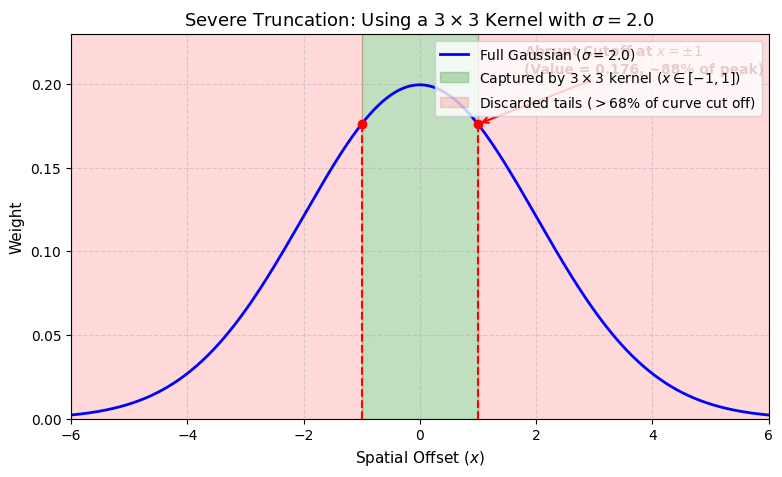

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Define spatial domain
x = np.linspace(-6, 6, 1000)
sigma = 2.0

def gaussian_1d(x, sigma):
    return (1.0 / (sigma * np.sqrt(2 * np.pi))) * np.exp(-x**2 / (2 * sigma**2))

y = gaussian_1d(x, sigma)

plt.figure(figsize=(9, 5))
plt.plot(x, y, color='blue', linewidth=2, label=f"Full Gaussian ($\sigma={sigma}$)")

# Highlight retained 3x3 zone (radius = 1, x in [-1, 1])
plt.axvspan(-1, 1, color='green', alpha=0.25, label='Captured by $3 \\times 3$ kernel ($x \\in [-1, 1]$)')

# Highlight truncated tail zones
plt.axvspan(-6, -1, color='red', alpha=0.15, label='Discarded tails ($> 68\\%$ of curve cut off)')
plt.axvspan(1, 6, color='red', alpha=0.15)

# Boundary cutoff markers
cutoff_val = gaussian_1d(1.0, sigma)
plt.plot([-1, 1], [cutoff_val, cutoff_val], 'ro', markersize=6)
plt.vlines([-1, 1], 0, cutoff_val, color='red', linestyle='--', linewidth=1.5)

plt.annotate(f'Abrupt Cutoff at $x=\\pm 1$\n(Value = {cutoff_val:.3f}, ~88% of peak)',
             xy=(1, cutoff_val), xytext=(1.8, cutoff_val + 0.03),
             arrowprops=dict(arrowstyle="->", color='red', lw=1.5),
             fontsize=10, fontweight='bold', color='darkred')

plt.title("Severe Truncation: Using a $3 \\times 3$ Kernel with $\\sigma = 2.0$", fontsize=13)
plt.xlabel("Spatial Offset ($x$)", fontsize=11)
plt.ylabel("Weight", fontsize=11)
plt.ylim(0, 0.23)
plt.xlim(-6, 6)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper right", fontsize=10)
plt.show()